Saving input.jpg to input (3).jpg
Image dimensions: 481 x 321


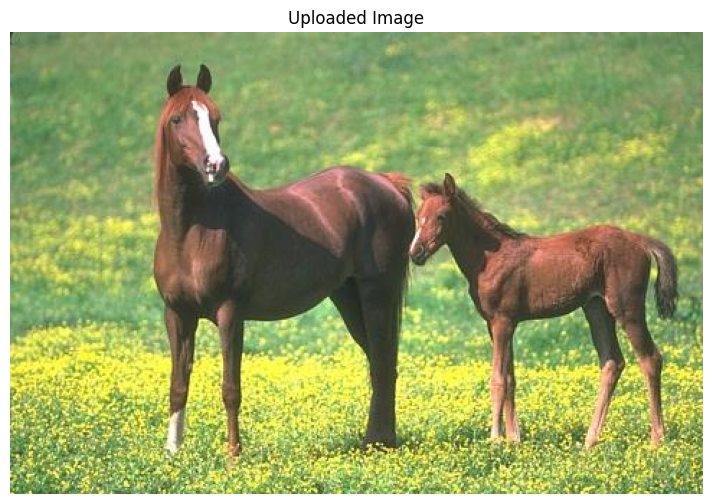

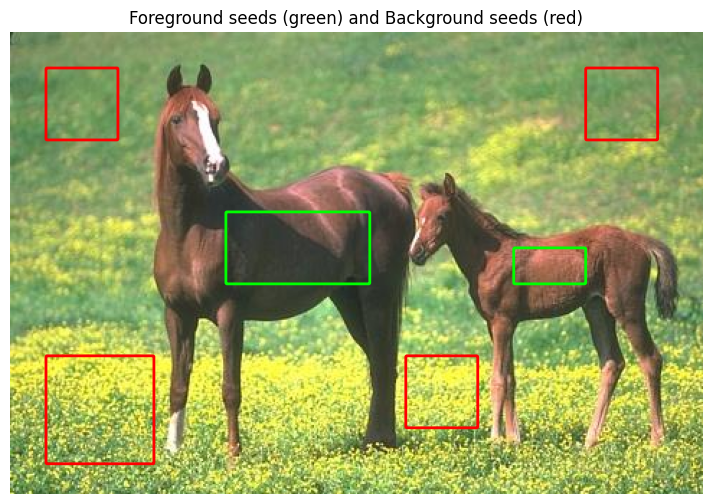


========== PART (a): MAXIMUM LIKELIHOOD ==========


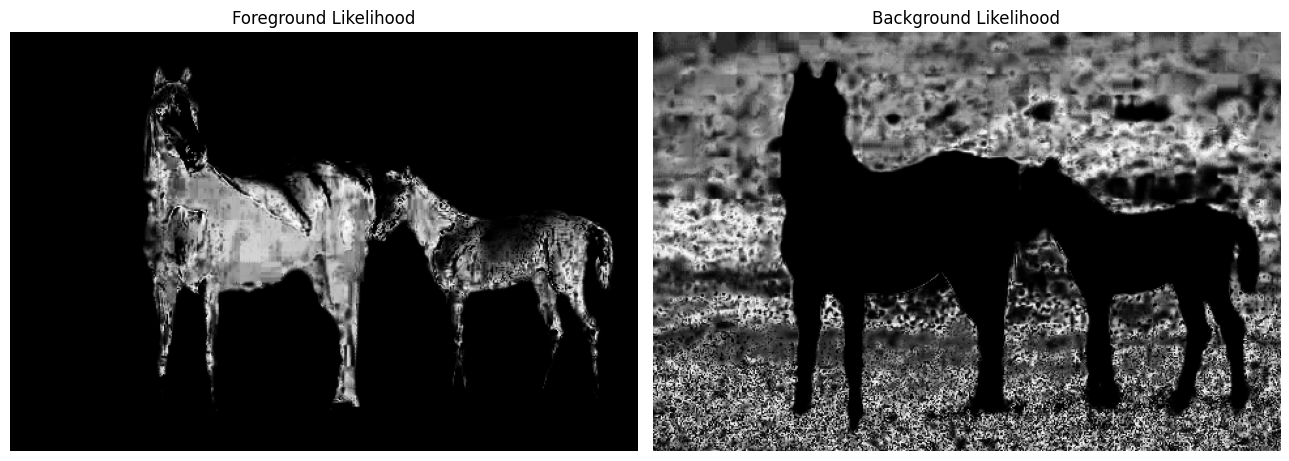

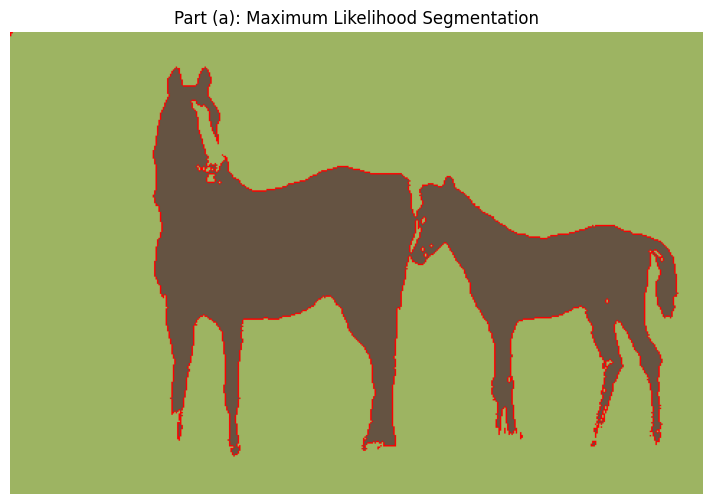


========== PART (b): K-MEANS ==========
Iteration 1: WCSS = 467729655.71
Iteration 2: WCSS = 466730485.90
Iteration 3: WCSS = 466591376.24
Iteration 4: WCSS = 466544800.36
Iteration 5: WCSS = 466531599.15
Iteration 6: WCSS = 466526719.79
Iteration 7: WCSS = 466524859.31
Iteration 8: WCSS = 466524298.65
Iteration 9: WCSS = 466523929.38
Iteration 10: WCSS = 466523798.38
Iteration 11: WCSS = 466523783.45
Iteration 12: WCSS = 466523782.49
Iteration 13: WCSS = 466523781.05
Iteration 14: WCSS = 466523779.57
Iteration 15: WCSS = 466523779.14


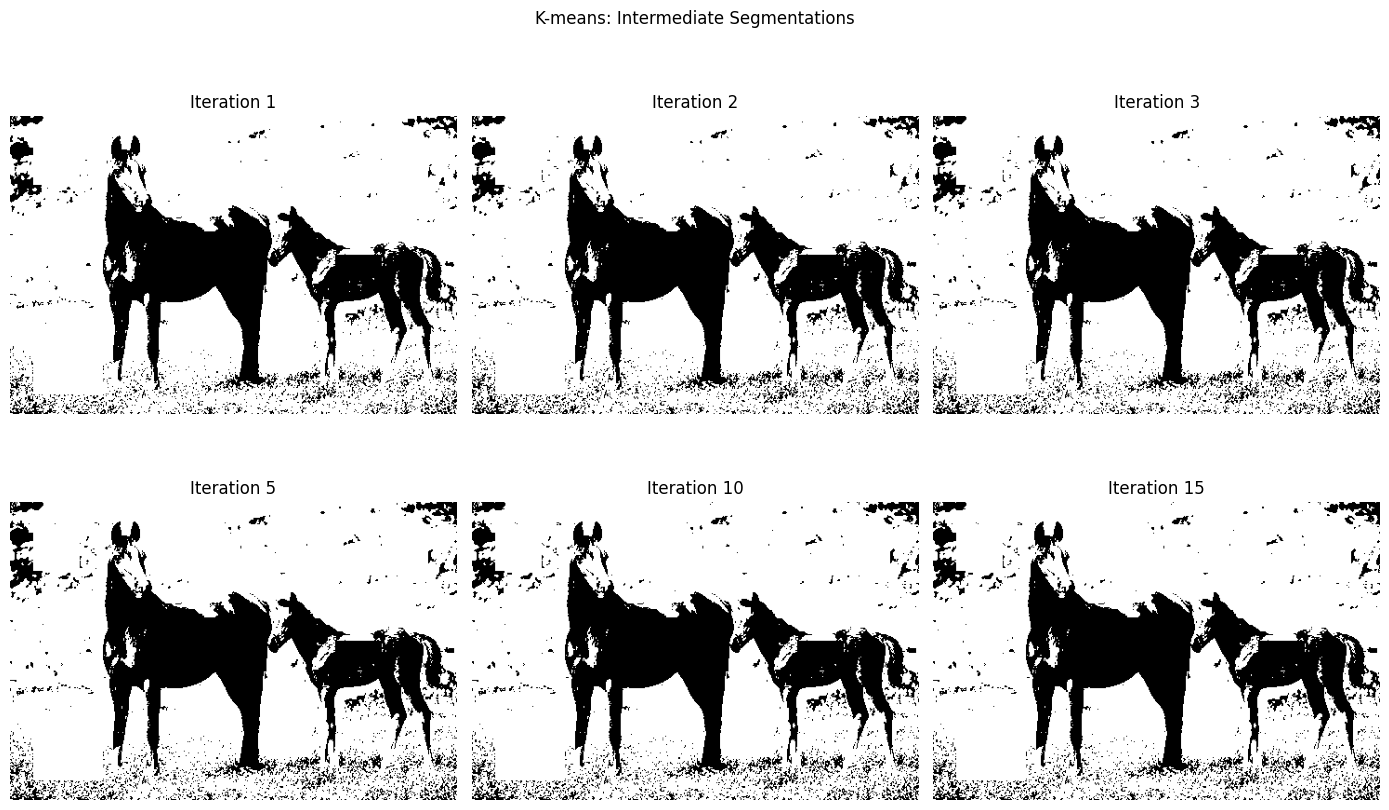

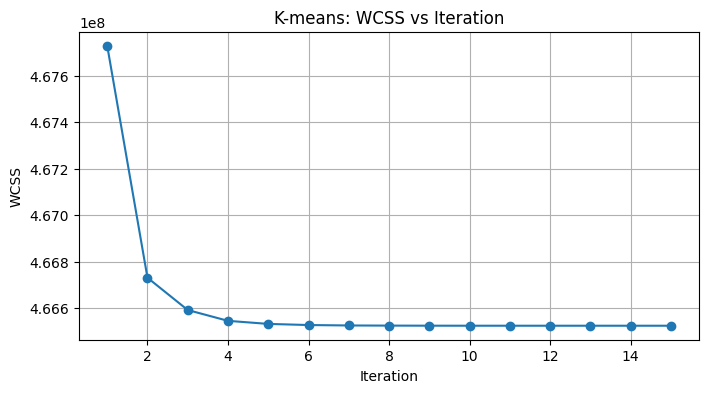

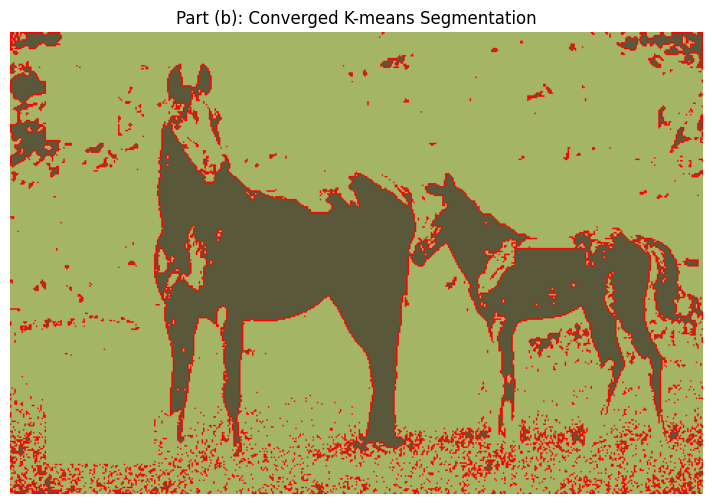


========== PART (c): GRAPH CUTS ==========
Maximum flow: 589.047


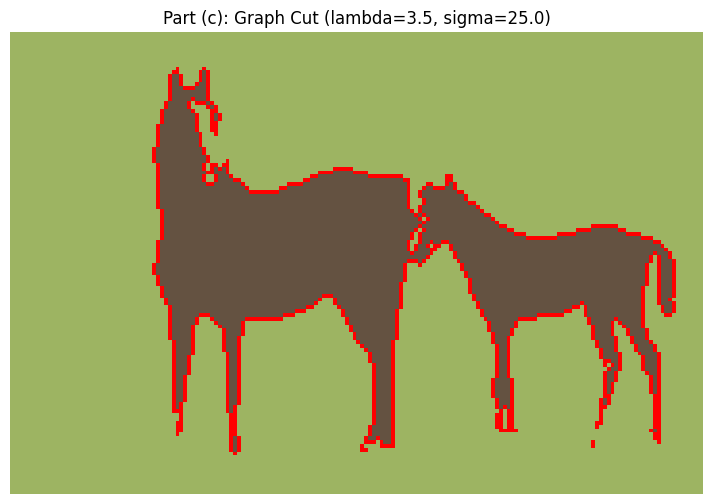

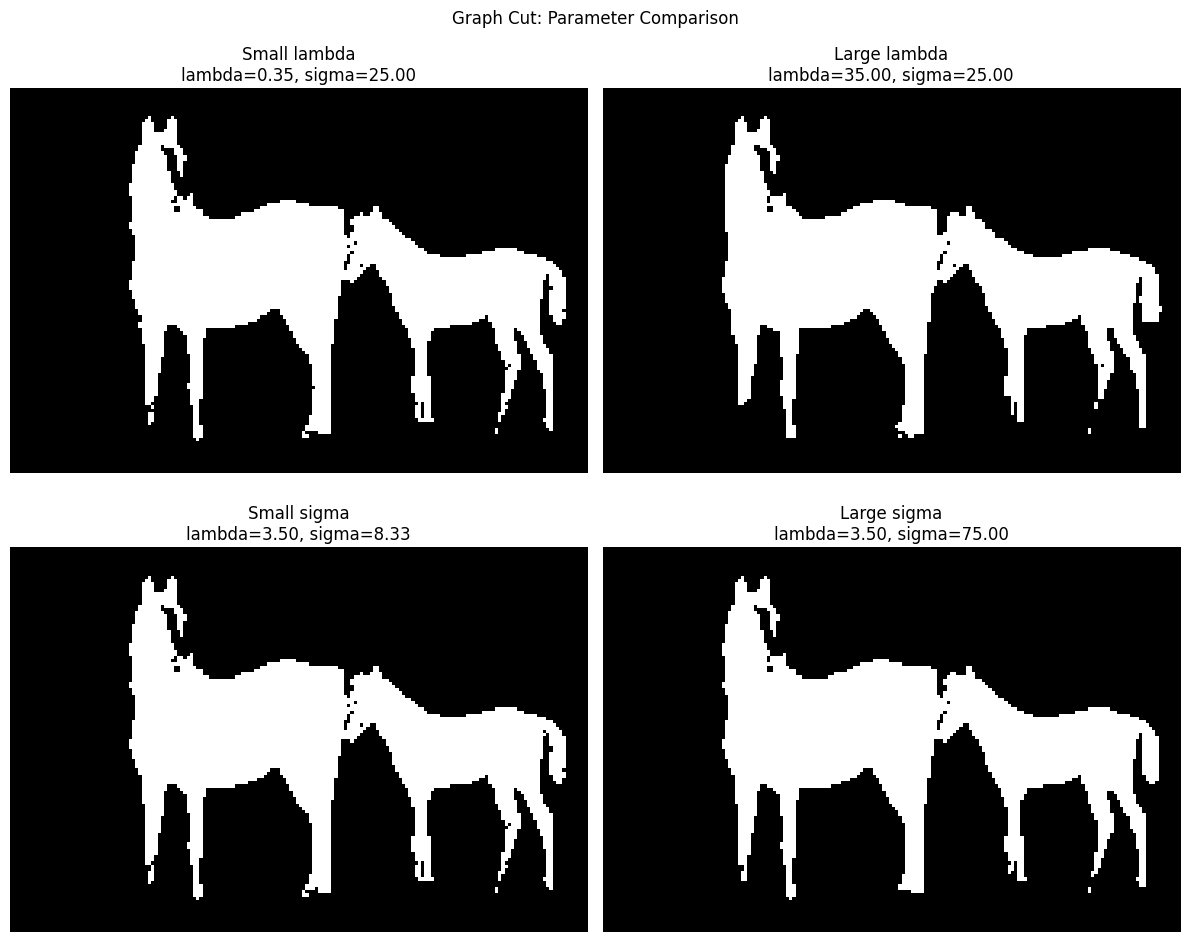


========== PART (d): GRABCUT-LIKE SEGMENTATION ==========
Graph image dimensions: 180 x 120
Initial foreground pixels: 14734
Initial background pixels: 5360


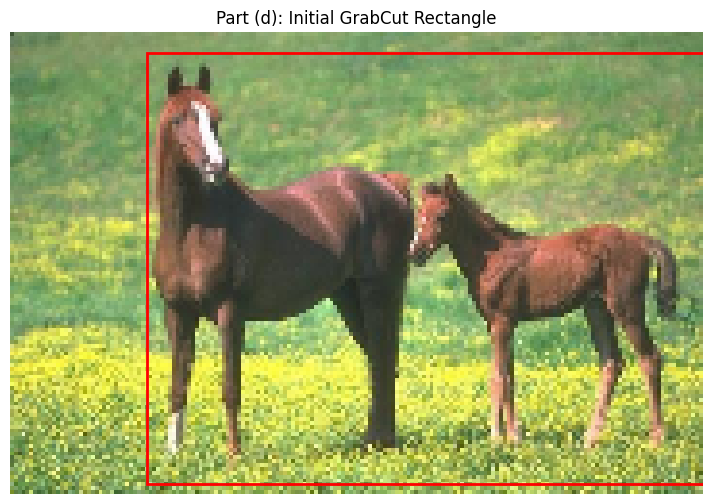

Iteration 1: FG pixels = 6383, BG pixels = 15217, Flow = 1428.682
Iteration 2: FG pixels = 5779, BG pixels = 15821, Flow = 864.967
Iteration 3: FG pixels = 5530, BG pixels = 16070, Flow = 582.708
Iteration 4: FG pixels = 5442, BG pixels = 16158, Flow = 475.946
Iteration 5: FG pixels = 5407, BG pixels = 16193, Flow = 463.109
Iteration 6: FG pixels = 5388, BG pixels = 16212, Flow = 462.457


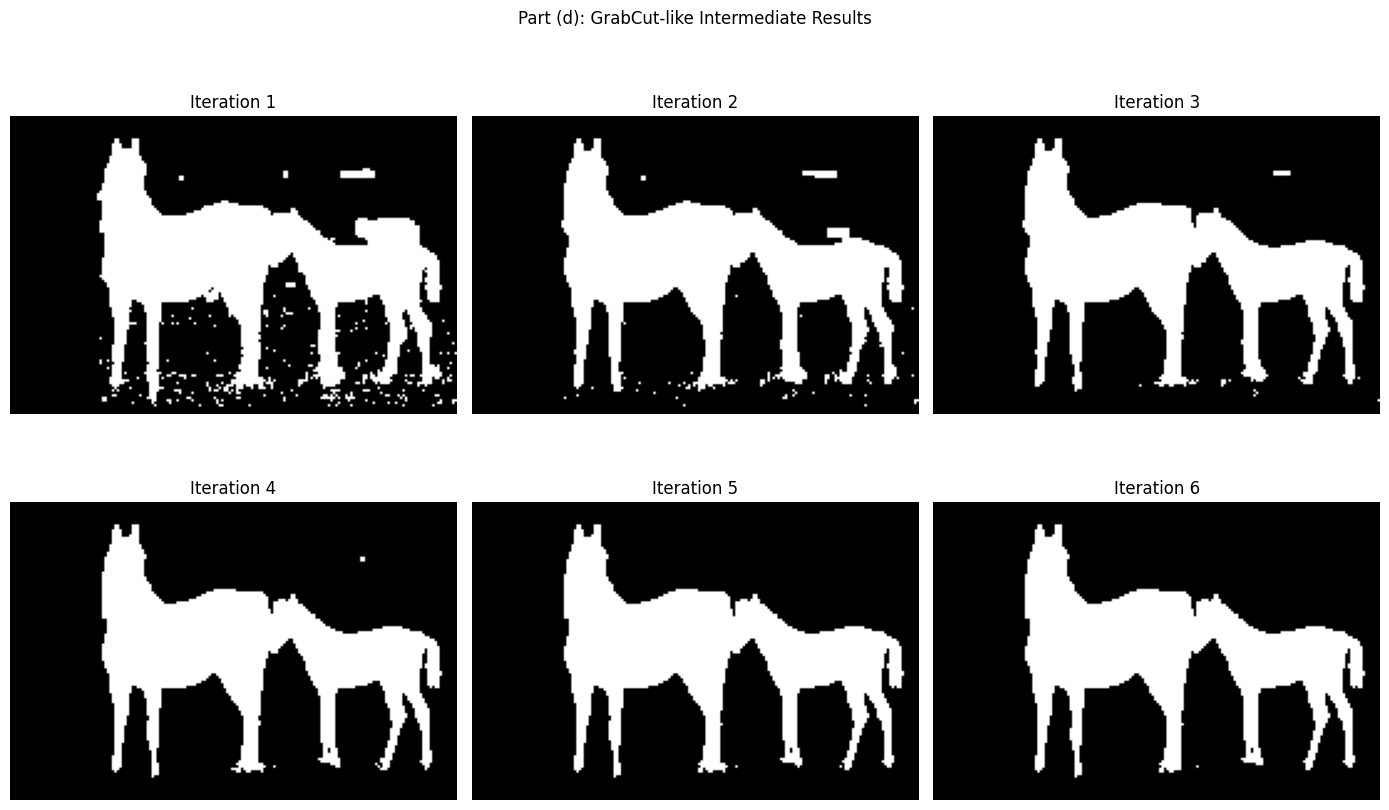

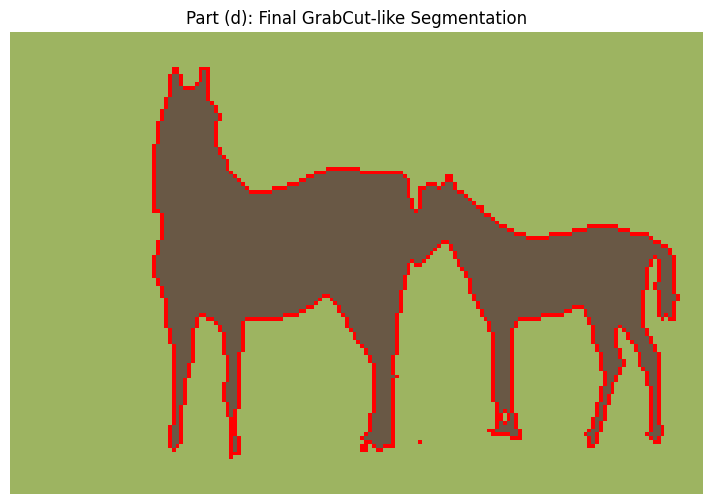

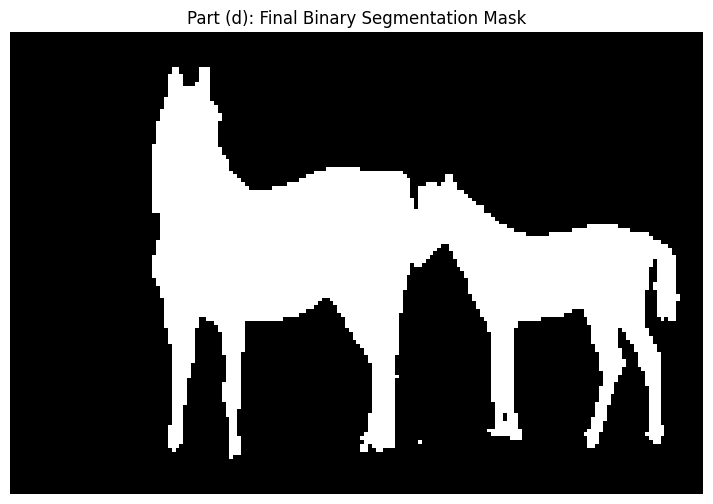


========== ALL FOUR PARTS COMPLETED ==========


In [5]:

# ================================================================
# GRABCUT ASSIGNMENT: PARTS (a), (b), (c), (d)
# Complete Google Colab implementation
# ================================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.csgraph import maximum_flow, breadth_first_order
from scipy.ndimage import binary_erosion
from google.colab import files
from PIL import Image
import io
import warnings
warnings.filterwarnings("ignore")


# ================================================================
# 1. UPLOAD IMAGE AND CONFIGURATION
# ================================================================

uploaded = files.upload()
filename = next(iter(uploaded))

img = np.array(
    Image.open(io.BytesIO(uploaded[filename])).convert("RGB")
)

# Resize image
MAX_SIDE = 512
h, w = img.shape[:2]
scale = min(1, MAX_SIDE / max(h, w))

img = cv2.resize(
    img, (int(w*scale), int(h*scale))
).astype(np.float64)

H, W = img.shape[:2]

print("Image dimensions:", W, "x", H)

plt.figure(figsize=(10, 6))
plt.imshow(img.astype(np.uint8))
plt.title("Uploaded Image")
plt.axis("off")
plt.show()


# ------------------------------------------------
# ALL RECTANGLES USE PIXEL COORDINATES
# Format: (x1, y1, x2, y2)
# ------------------------------------------------

# Known foreground regions: horses
FG_BOXES = [
    (150, 125, 250, 175),
    (350, 150, 400, 175)
]

# Known background regions: grass
BG_BOXES = [
    (25, 25, 75, 75),
    (400, 25, 450, 75),
    (25, 225, 100, 300),
    (275, 225, 325, 275)
]

# One rectangle enclosing both horses for Part (d)
GRAB_RECT = (95, 15, 505, 315)

# Graph cut parameters
LAMBDA = 3.5
SIGMA = 25.0

KMEANS_ITER = 15
GRABCUT_ITER = 6

GRAPH_MAX_SIDE = 180


# ================================================================
# 2. HELPER FUNCTIONS
# ================================================================

def rectangle_mask(shape, boxes):
    h, w = shape
    mask = np.zeros((h, w), dtype=bool)

    for x1, y1, x2, y2 in boxes:
        x1 = max(0, min(w, int(x1)))
        x2 = max(0, min(w, int(x2)))
        y1 = max(0, min(h, int(y1)))
        y2 = max(0, min(h, int(y2)))

        mask[y1:y2, x1:x2] = True

    return mask


def get_boundary(mask):
    return mask ^ binary_erosion(mask)


def show_segmentation(image, mask, title):

    mask = mask.astype(bool)

    if mask.sum() == 0 or (~mask).sum() == 0:
        print("Warning: One segmentation class is empty.")
        return

    fg_mean = image[mask].mean(axis=0)
    bg_mean = image[~mask].mean(axis=0)

    result = np.zeros_like(image)

    result[mask] = fg_mean
    result[~mask] = bg_mean

    boundary = get_boundary(mask)
    result[boundary] = [255, 0, 0]

    plt.figure(figsize=(9, 6))
    plt.imshow(np.clip(result, 0, 255).astype(np.uint8))
    plt.title(title)
    plt.axis("off")
    plt.show()

    return result


def fit_gaussian(X):

    X = np.asarray(X).reshape(-1, 3)

    assert len(X) > 10, "Not enough pixels to fit Gaussian."

    mean = X.mean(axis=0)

    cov = np.cov(X, rowvar=False)
    cov += np.eye(3) * 25.0

    sign, logdet = np.linalg.slogdet(cov)
    inv = np.linalg.inv(cov)

    return mean, inv, logdet


def gaussian_log_likelihood(image, gaussian):

    mean, inv, logdet = gaussian

    diff = image - mean

    mahal = np.einsum(
        "...i,ij,...j->...", diff, inv, diff
    )

    return -0.5 * (
        mahal + logdet + 3*np.log(2*np.pi)
    )


def fit_two_gaussians(image, fg_mask, bg_mask):

    assert fg_mask.sum() > 10
    assert bg_mask.sum() > 10

    fg = fit_gaussian(image[fg_mask])
    bg = fit_gaussian(image[bg_mask])

    return fg, bg


# ================================================================
# 3. INITIAL FOREGROUND AND BACKGROUND SEEDS
# ================================================================

fg_seed = rectangle_mask((H, W), FG_BOXES)
bg_seed = rectangle_mask((H, W), BG_BOXES)

assert fg_seed.any(), "Foreground seeds are empty."
assert bg_seed.any(), "Background seeds are empty."
assert not np.any(fg_seed & bg_seed), "Seeds overlap."

fg_gaussian, bg_gaussian = fit_two_gaussians(
    img, fg_seed, bg_seed
)

plt.figure(figsize=(10, 6))
plt.imshow(img.astype(np.uint8))

plt.contour(
    fg_seed, levels=[0.5],
    colors="lime", linewidths=2
)

plt.contour(
    bg_seed, levels=[0.5],
    colors="red", linewidths=2
)

plt.title("Foreground seeds (green) and Background seeds (red)")
plt.axis("off")
plt.show()


# ================================================================
# PART (a): MAXIMUM LIKELIHOOD CLASSIFICATION
# ================================================================

print("\n========== PART (a): MAXIMUM LIKELIHOOD ==========")

log_fg = gaussian_log_likelihood(img, fg_gaussian)
log_bg = gaussian_log_likelihood(img, bg_gaussian)

# Relative likelihood visualization
lik_fg = np.exp(
    np.clip(log_fg - np.max(log_fg), -40, 0)
)

lik_bg = np.exp(
    np.clip(log_bg - np.max(log_bg), -40, 0)
)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].imshow(lik_fg, cmap="gray")
ax[0].set_title("Foreground Likelihood")
ax[0].axis("off")

ax[1].imshow(lik_bg, cmap="gray")
ax[1].set_title("Background Likelihood")
ax[1].axis("off")

plt.tight_layout()
plt.show()

# Maximum likelihood classification
ml_mask = log_fg > log_bg

# Preserve known pixels
ml_mask[fg_seed] = True
ml_mask[bg_seed] = False

show_segmentation(
    img, ml_mask,
    "Part (a): Maximum Likelihood Segmentation"
)


# ================================================================
# PART (b): K-MEANS CLUSTERING
# ================================================================

print("\n========== PART (b): K-MEANS ==========")

pixels = img.reshape(-1, 3)

fg_flat = fg_seed.flatten()
bg_flat = bg_seed.flatten()

# Initial means from marked pixels
centers = np.array([
    img[fg_seed].mean(axis=0),
    img[bg_seed].mean(axis=0)
])

labels = np.zeros(len(pixels), dtype=np.int32)

wcss_values = []
snapshots = []

for iteration in range(KMEANS_ITER):

    d_fg = np.sum(
        (pixels - centers[0])**2, axis=1
    )

    d_bg = np.sum(
        (pixels - centers[1])**2, axis=1
    )

    new_labels = (d_bg < d_fg).astype(np.int32)

    # Preserve marked pixels
    new_labels[fg_flat] = 0
    new_labels[bg_flat] = 1

    # Update means
    for k in range(2):

        selected = pixels[new_labels == k]

        if len(selected):
            centers[k] = selected.mean(axis=0)

    labels = new_labels

    # Calculate WCSS
    wcss = 0

    for k in range(2):

        selected = pixels[labels == k]

        if len(selected):
            wcss += np.sum(
                (selected - centers[k])**2
            )

    wcss_values.append(wcss)

    if iteration in [0, 1, 2, 4, 9, KMEANS_ITER-1]:

        snapshots.append(
            (iteration+1, labels.reshape(H, W).copy())
        )

    print(
        f"Iteration {iteration+1}: WCSS = {wcss:.2f}"
    )


# Display intermediate iterations
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, (it, mask) in zip(axes.ravel(), snapshots):

    ax.imshow(mask, cmap="gray")
    ax.set_title(f"Iteration {it}")
    ax.axis("off")

plt.suptitle("K-means: Intermediate Segmentations")
plt.tight_layout()
plt.show()


# WCSS plot
plt.figure(figsize=(8, 4))

plt.plot(
    range(1, KMEANS_ITER+1),
    wcss_values,
    marker="o"
)

plt.xlabel("Iteration")
plt.ylabel("WCSS")
plt.title("K-means: WCSS vs Iteration")
plt.grid(True)
plt.show()


kmeans_mask = labels.reshape(H, W) == 0

show_segmentation(
    img, kmeans_mask,
    "Part (b): Converged K-means Segmentation"
)


# ================================================================
# PART (c): GRAPH CUTS USING SCIPY MAXIMUM FLOW
# ================================================================

print("\n========== PART (c): GRAPH CUTS ==========")


def graph_cut(
    image,
    fg_gauss,
    bg_gauss,
    fg_fixed,
    bg_fixed,
    lam=3.5,
    sigma=25.0
):

    h, w = image.shape[:2]
    n = h*w

    # ------------------------------------------------
    # Unary costs: negative log likelihood
    # ------------------------------------------------

    lf = gaussian_log_likelihood(image, fg_gauss)
    lb = gaussian_log_likelihood(image, bg_gauss)

    Df = -lf
    Db = -lb

    # Normalize costs per pixel
    minimum = np.minimum(Df, Db)

    Df -= minimum
    Db -= minimum

    # Hard seed constraints
    INF = 1e6

    Df[bg_fixed] = INF
    Db[fg_fixed] = INF

    # ------------------------------------------------
    # Construct graph
    # ------------------------------------------------

    source = n
    sink = n+1

    nodes = np.arange(n)

    rows = []
    cols = []
    vals = []

    # Source -> pixel: background assignment cost
    # Pixel -> sink: foreground assignment cost

    rows.extend([
        np.full(n, source),
        nodes
    ])

    cols.extend([
        nodes,
        np.full(n, sink)
    ])

    vals.extend([
        Db.flatten(),
        Df.flatten()
    ])

    # ------------------------------------------------
    # Pairwise costs: 4-connected neighbourhood
    # ------------------------------------------------

    for dy, dx in [(0, 1), (1, 0)]:

        diff = (
            image[:h-dy or None, :w-dx or None]
            - image[dy:, dx:]
        )

        dist2 = np.sum(diff**2, axis=2)

        weight = lam * np.exp(
            -dist2/(2*sigma**2)
        )

        p = (
            np.arange(h-dy)[:, None]*w
            + np.arange(w-dx)[None, :]
        ).flatten()

        q = (
            (np.arange(h-dy)[:, None]+dy)*w
            + (np.arange(w-dx)[None, :]+dx)
        ).flatten()

        capacities = weight.flatten()

        rows.extend([p, q])
        cols.extend([q, p])
        vals.extend([capacities, capacities])

    # ------------------------------------------------
    # Convert to integer capacities
    # ------------------------------------------------

    rows = np.concatenate([
        np.asarray(x).ravel() for x in rows
    ])

    cols = np.concatenate([
        np.asarray(x).ravel() for x in cols
    ])

    vals = np.concatenate([
        np.asarray(x).ravel() for x in vals
    ])

    SCALE = 1000

    capacities = np.clip(
        np.rint(vals*SCALE),
        0,
        2_000_000_000
    ).astype(np.int32)

    graph = sparse.coo_matrix(
        (capacities, (rows, cols)),
        shape=(n+2, n+2),
        dtype=np.int32
    ).tocsr()

    graph.sum_duplicates()

    # ------------------------------------------------
    # Maximum flow / minimum cut
    # ------------------------------------------------

    result = maximum_flow(
        graph, source, sink
    )

    # Residual graph
    residual = graph - result.flow

    residual.data = (
        residual.data > 0
    ).astype(np.int8)

    residual.eliminate_zeros()

    # Nodes reachable from source belong to foreground
    reachable = breadth_first_order(
        residual,
        source,
        directed=True,
        return_predecessors=False
    )

    mask = np.zeros(n, dtype=bool)

    mask[reachable[reachable < n]] = True

    return mask.reshape(h, w), result.flow_value/SCALE


# ------------------------------------------------
# Reduce image size for graph cuts
# ------------------------------------------------

gscale = min(
    1, GRAPH_MAX_SIDE/max(H, W)
)

gh = max(1, int(H*gscale))
gw = max(1, int(W*gscale))

graph_img = cv2.resize(
    img, (gw, gh)
).astype(np.float64)


# Resize seeds using nearest-neighbour interpolation
fg_small = cv2.resize(
    fg_seed.astype(np.uint8),
    (gw, gh),
    interpolation=cv2.INTER_NEAREST
).astype(bool)

bg_small = cv2.resize(
    bg_seed.astype(np.uint8),
    (gw, gh),
    interpolation=cv2.INTER_NEAREST
).astype(bool)

assert not np.any(fg_small & bg_small)

fg_g_small, bg_g_small = fit_two_gaussians(
    graph_img, fg_small, bg_small
)


# Default graph cut
gc_mask, flow = graph_cut(
    graph_img,
    fg_g_small,
    bg_g_small,
    fg_small,
    bg_small,
    LAMBDA,
    SIGMA
)

print("Maximum flow:", flow)

show_segmentation(
    graph_img,
    gc_mask,
    f"Part (c): Graph Cut (lambda={LAMBDA}, sigma={SIGMA})"
)


# ------------------------------------------------
# Parameter comparison
# ------------------------------------------------

settings = [
    (LAMBDA/10, SIGMA, "Small lambda"),
    (LAMBDA*10, SIGMA, "Large lambda"),
    (LAMBDA, SIGMA/3, "Small sigma"),
    (LAMBDA, SIGMA*3, "Large sigma")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (lam, sig, name) in zip(
    axes.ravel(), settings
):

    mask, _ = graph_cut(
        graph_img,
        fg_g_small,
        bg_g_small,
        fg_small,
        bg_small,
        lam,
        sig
    )

    ax.imshow(mask, cmap="gray")

    ax.set_title(
        f"{name}\nlambda={lam:.2f}, sigma={sig:.2f}"
    )

    ax.axis("off")

plt.suptitle("Graph Cut: Parameter Comparison")
plt.tight_layout()
plt.show()


# ================================================================
# PART (d): GRABCUT-LIKE ITERATIVE SEGMENTATION
# ================================================================

print("\n========== PART (d): GRABCUT-LIKE SEGMENTATION ==========")

# IMPORTANT:
# GRAB_RECT is in ORIGINAL resized-image pixel coordinates.
# Convert it to graph-image coordinates correctly.

rx1, ry1, rx2, ry2 = GRAB_RECT

x1 = int(rx1 * gw / W)
x2 = int(rx2 * gw / W)

y1 = int(ry1 * gh / H)
y2 = int(ry2 * gh / H)

# Clamp rectangle to image dimensions
x1 = np.clip(x1, 0, gw-1)
x2 = np.clip(x2, 1, gw)

y1 = np.clip(y1, 0, gh-1)
y2 = np.clip(y2, 1, gh)

assert x2 > x1 and y2 > y1, "Invalid GrabCut rectangle."

# ------------------------------------------------
# Initialize foreground/background from rectangle
# ------------------------------------------------

rect_mask = np.zeros((gh, gw), dtype=bool)

rect_mask[y1:y2, x1:x2] = True

# Rectangle interior = initial foreground
interior = binary_erosion(
    rect_mask,
    iterations=3
)

if interior.sum() < 10:
    interior = rect_mask.copy()

# Pixels outside rectangle = initial background
initial_fg = graph_img[interior]
initial_bg = graph_img[~rect_mask]

assert len(initial_fg) > 10
assert len(initial_bg) > 10

fg_g = fit_gaussian(initial_fg)
bg_g = fit_gaussian(initial_bg)

# Outside rectangle is definite background
fixed_bg = ~rect_mask

# No manually specified foreground pixels
fixed_fg = np.zeros((gh, gw), dtype=bool)

print("Graph image dimensions:", gw, "x", gh)
print("Initial foreground pixels:", len(initial_fg))
print("Initial background pixels:", len(initial_bg))


# Visualize initial rectangle
plt.figure(figsize=(9, 6))

plt.imshow(graph_img.astype(np.uint8))

plt.gca().add_patch(
    plt.Rectangle(
        (x1, y1),
        x2-x1,
        y2-y1,
        fill=False,
        edgecolor="red",
        linewidth=2
    )
)

plt.title("Part (d): Initial GrabCut Rectangle")
plt.axis("off")
plt.show()


# ------------------------------------------------
# Alternating Gaussian fitting and graph cut
# ------------------------------------------------

grab_snapshots = []

for iteration in range(GRABCUT_ITER):

    # E-step: update class memberships using graph cut
    new_mask, flow = graph_cut(
        graph_img,
        fg_g,
        bg_g,
        fixed_fg,
        fixed_bg,
        LAMBDA,
        SIGMA
    )

    # M-step: refit Gaussian models
    if (
        new_mask.sum() > 10
        and (~new_mask).sum() > 10
    ):

        fg_g = fit_gaussian(
            graph_img[new_mask]
        )

        bg_g = fit_gaussian(
            graph_img[~new_mask]
        )

    grab_mask = new_mask

    grab_snapshots.append(
        grab_mask.copy()
    )

    print(
        f"Iteration {iteration+1}: "
        f"FG pixels = {grab_mask.sum()}, "
        f"BG pixels = {(~grab_mask).sum()}, "
        f"Flow = {flow:.3f}"
    )


# ------------------------------------------------
# Display intermediate iterations
# ------------------------------------------------

fig, axes = plt.subplots(
    2, 3, figsize=(14, 9)
)

for i, ax in enumerate(axes.ravel()):

    if i < len(grab_snapshots):

        ax.imshow(
            grab_snapshots[i],
            cmap="gray"
        )

        ax.set_title(
            f"Iteration {i+1}"
        )

    ax.axis("off")

plt.suptitle(
    "Part (d): GrabCut-like Intermediate Results"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------
# Final segmentation
# ------------------------------------------------

show_segmentation(
    graph_img,
    grab_mask,
    "Part (d): Final GrabCut-like Segmentation"
)

plt.figure(figsize=(9, 6))

plt.imshow(
    grab_mask,
    cmap="gray"
)

plt.title(
    "Part (d): Final Binary Segmentation Mask"
)

plt.axis("off")
plt.show()


print("\n========== ALL FOUR PARTS COMPLETED ==========")
